# GMO and Forecasting SPY: supporting code
**FINM 36700** · Elektra Ballas, Edouard Lavalard, Hoang Pham, Nikita Rodin

In [1]:
import matplotlib.pyplot as plt
import pandas as pd, numpy as np, statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import warnings; warnings.filterwarnings('ignore')

In [2]:
FILE1 = 'spy_forecasting_data.xlsx'
P = 12
SPY = pd.read_excel(FILE1, sheet_name='spy returns', index_col=0)['SPY']
T3M = pd.read_excel(FILE1, sheet_name='risk-free rate', index_col=0)['T3M']
SIG = pd.read_excel(FILE1, sheet_name='signals', index_col=0)
D = (SPY - T3M.shift(1)).rename('SPY').to_frame().join(SIG.shift(1)).dropna()  # r_t (excess) next to x_{t-1}
Y, X = D['SPY'], D[SIG.columns]
MODELS = {'DP': ['DP'], 'EP': ['EP'], 'ALL': list(SIG.columns)}
BURN = 5 * P
NULL = Y.expanding().mean().shift(1)

def stats(R, p=P):
    m, v = R.mean() * p, R.std() * np.sqrt(p)
    W_ = (1 + R).cumprod()
    return pd.DataFrame({'mean': m, 'vol': v, 'sharpe': m / v, 'min': R.min(),
                         'max drawdown': (W_ / W_.cummax().clip(lower=1) - 1).min()})

def strategies(F):
    S = F.mul(100).mul(Y.loc[F.index], axis=0)  # w_t = 100 * forecast of r_{t+1}, both dated t+1
    S['Passive'] = Y.loc[F.index]
    return S

def r2_oos(F):
    e0 = ((Y - NULL).loc[F.index] ** 2).sum()
    return pd.Series({c: 1 - ((Y.loc[F.index] - F[c]) ** 2).sum() / e0 for c in F})

def oos(make, cols, scale=False):
    f = pd.Series(np.nan, index=Y.index)
    for t in Y.index[BURN - 1:]:
        Xt, yt, xn = X.loc[:t, cols], Y.loc[:t], SIG.loc[[t], cols]
        if scale:
            sx, sy = StandardScaler().fit(Xt), StandardScaler().fit(yt.to_frame())
            m = make().fit(sx.transform(Xt), sy.transform(yt.to_frame()).ravel())
            f[t] = sy.inverse_transform(m.predict(sx.transform(xn)).reshape(-1, 1))[0, 0]
        else:
            f[t] = make().fit(Xt, yt).predict(xn)[0]
    return f.shift(1)  # dated by the month forecasted

RF_ML = lambda: RandomForestRegressor(max_depth=5, n_estimators=100, random_state=0)
NN_ML = lambda: MLPRegressor(hidden_layer_sizes=(50,), random_state=0)

# Part I. Forecasting SPY
# 1. In-sample forecast regressions
## 1.1

,alpha,DP,EP,CAPE,BP,T10YR,CREDIT,VIX,r-squared
DP,-0.008947,0.008652,NaN,NaN,NaN,NaN,NaN,NaN,0.008750
EP,-0.008017,NaN,0.002882,NaN,NaN,NaN,NaN,NaN,0.007465
ALL,0.072540,0.012636,0.002064,-0.001485,-0.001079,-0.00435,-0.000163,0.001286,0.053954


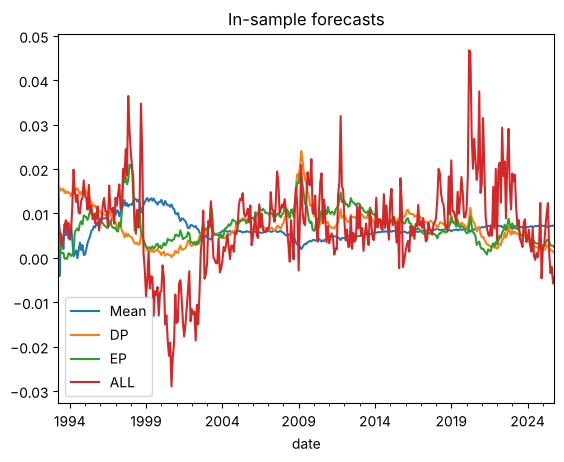

In [3]:
F_IS, REG = pd.DataFrame({'Mean': NULL}), {}
for k, c in MODELS.items():
    fit = LinearRegression().fit(X[c], Y)
    F_IS[k] = fit.predict(X[c])
    REG[k] = pd.Series({'alpha': fit.intercept_} | dict(zip(c, fit.coef_)) | {'r-squared': fit.score(X[c], Y)})
F_IS, REG = F_IS.dropna(), pd.DataFrame(REG).T[['alpha'] + list(SIG.columns) + ['r-squared']]
display(REG)
F_IS.plot(title='In-sample forecasts'); plt.show()

## 1.2

,mean,vol,sharpe,min,max drawdown
Mean,0.050945,0.107716,0.472958,-0.183419,-0.430814
DP,0.083097,0.132667,0.626359,-0.221043,-0.630078
EP,0.080998,0.135224,0.598992,-0.205894,-0.610805
ALL,0.182459,0.254282,0.717545,-0.587785,-0.649179
Passive,0.087792,0.147808,0.593958,-0.165941,-0.561393


,Mean,DP,EP,ALL,Passive
Mean,1.000000,0.624548,0.751903,0.479780,0.918859
DP,0.624548,1.000000,0.915312,0.644570,0.843669
EP,0.751903,0.915312,1.000000,0.635028,0.888319
ALL,0.479780,0.644570,0.635028,1.000000,0.596968
Passive,0.918859,0.843669,0.888319,0.596968,1.000000


,mean,min,max
Mean,0.662407,-0.407000,1.991148
DP,0.732785,0.018535,2.405739
EP,0.735720,-0.020913,2.106191
ALL,0.736271,-2.893576,4.676158


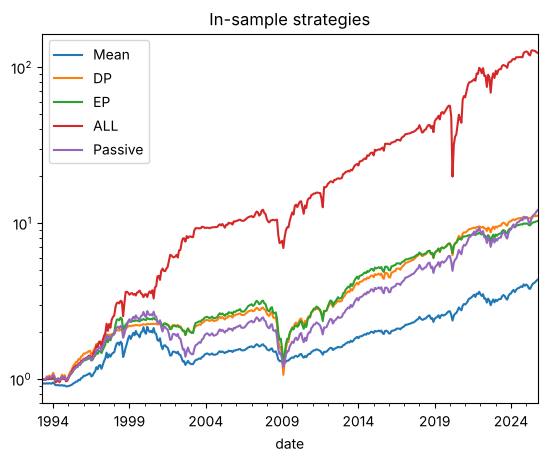

In [4]:
S_IS = strategies(F_IS)
display(stats(S_IS), S_IS.corr(), (100 * F_IS).describe().T[['mean', 'min', 'max']])
(1 + S_IS).cumprod().plot(logy=True, title='In-sample strategies'); plt.show()

# 2. Out-of-sample forecasting
## 2.1

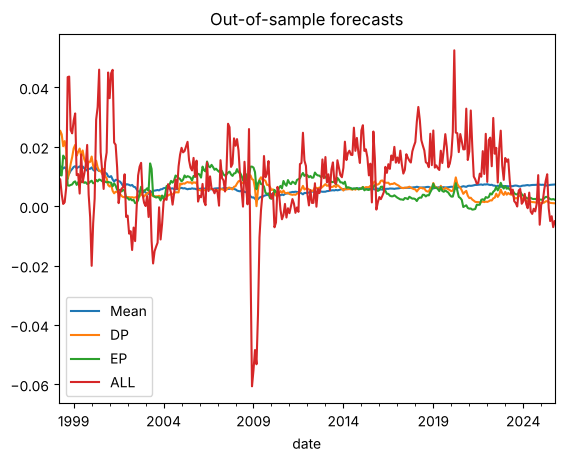

In [5]:
F_OOS = pd.DataFrame({'Mean': NULL} | {k: oos(LinearRegression, c) for k, c in MODELS.items()}).dropna()
F_OOS.plot(title='Out-of-sample forecasts'); plt.show()

## 2.2

Mean    0.000000
DP     -0.002867
EP     -0.002005
ALL    -0.057440
dtype: float64

,mean,vol,sharpe,min,max drawdown
Mean,0.042044,0.108119,0.388871,-0.183419,-0.430814
DP,0.042837,0.122711,0.349086,-0.277622,-0.511997
EP,0.044484,0.122198,0.364033,-0.229708,-0.543627
ALL,0.112679,0.340425,0.330995,-0.659759,-0.836851
Passive,0.076235,0.153575,0.496404,-0.165941,-0.561393


,Mean,DP,EP,ALL,Passive
Mean,1.000000,0.903387,0.835540,0.552769,0.925328
DP,0.903387,1.000000,0.906275,0.458371,0.847069
EP,0.835540,0.906275,1.000000,0.349919,0.883801
ALL,0.552769,0.458371,0.349919,1.000000,0.476121
Passive,0.925328,0.847069,0.883801,0.476121,1.000000


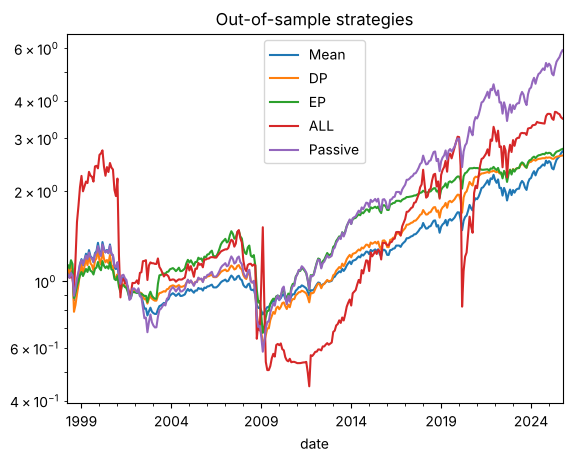

In [6]:
S_OOS = strategies(F_OOS)
display(r2_oos(F_OOS), stats(S_OOS), S_OOS.corr())
(1 + S_OOS).cumprod().plot(logy=True, title='Out-of-sample strategies'); plt.show()

## 2.3

,R2 IS,R2 OOS,Sharpe IS,"Sharpe IS, OOS window",Sharpe OOS
Mean,NaN,0.000000,0.472958,0.388871,0.388871
DP,0.008750,-0.002867,0.626359,0.524255,0.349086
EP,0.007465,-0.002005,0.598992,0.475853,0.364033
ALL,0.053954,-0.057440,0.717545,0.650591,0.330995
Passive,NaN,NaN,0.593958,0.496404,0.496404


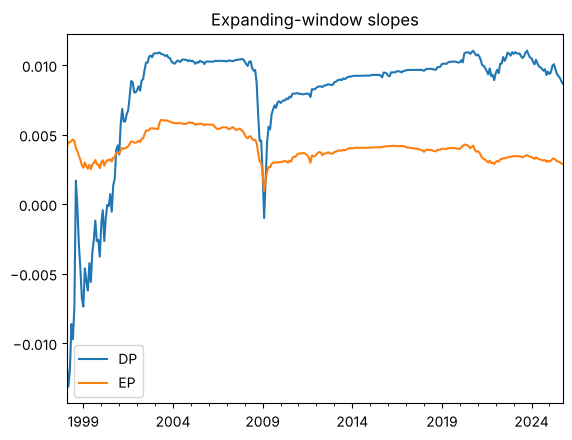

DP weight 1999         1.699919
DP weight 2000-2002    0.662035
dtype: float64

In [7]:
display(pd.DataFrame({'R2 IS': REG['r-squared'], 'R2 OOS': r2_oos(F_OOS), 'Sharpe IS': stats(S_IS)['sharpe'],
                      'Sharpe IS, OOS window': stats(S_IS.loc[F_OOS.index])['sharpe'],
                      'Sharpe OOS': stats(S_OOS)['sharpe']}).loc[S_IS.columns])
SLOPE = pd.DataFrame({k: pd.Series({t: LinearRegression().fit(X.loc[:t, [k]], Y.loc[:t]).coef_[0]
                                    for t in Y.index[BURN - 1:]}) for k in ['DP', 'EP']})
SLOPE.plot(title='Expanding-window slopes'); plt.show()
pd.Series({'DP weight 1999': 100 * F_OOS['DP'].loc['1999'].mean(),
           'DP weight 2000-2002': 100 * F_OOS['DP'].loc['2000':'2002'].mean()})

# 3. Machine learning forecasts
## 3.1

OLS    0.053954
RF     0.334450
NN     0.145909
dtype: float64

,mean,vol,sharpe,min,max drawdown
Mean,0.050945,0.107716,0.472958,-0.183419,-0.430814
OLS,0.182459,0.254282,0.717545,-0.587785,-0.649179
RF,0.520286,0.427238,1.217790,-0.061497,-0.119747
NN,0.317672,0.283275,1.121427,-0.448370,-0.478848
Passive,0.087792,0.147808,0.593958,-0.165941,-0.561393


,Mean,OLS,RF,NN,Passive
Mean,1.000000,0.479780,0.080568,0.359834,0.918859
OLS,0.479780,1.000000,0.353652,0.846455,0.596968
RF,0.080568,0.353652,1.000000,0.594987,0.129951
NN,0.359834,0.846455,0.594987,1.000000,0.429357
Passive,0.918859,0.596968,0.129951,0.429357,1.000000


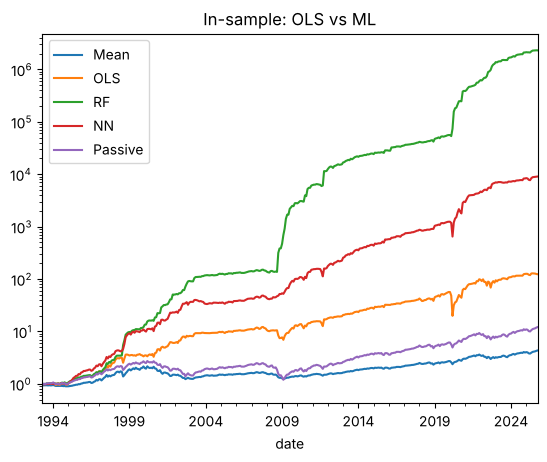

In [8]:
sx, sy = StandardScaler().fit(X), StandardScaler().fit(Y.to_frame())
nn = NN_ML().fit(sx.transform(X), sy.transform(Y.to_frame()).ravel())
PRED = pd.DataFrame({'OLS': LinearRegression().fit(X, Y).predict(X), 'RF': RF_ML().fit(X, Y).predict(X),
                     'NN': sy.inverse_transform(nn.predict(sx.transform(X)).reshape(-1, 1)).ravel()}, index=Y.index)
ML_IS = pd.concat([NULL.rename('Mean'), PRED], axis=1).dropna()
S_ML_IS = strategies(ML_IS)
display(PRED.apply(lambda f: r2_score(Y, f)), stats(S_ML_IS), S_ML_IS.corr())
(1 + S_ML_IS).cumprod().plot(logy=True, title='In-sample: OLS vs ML'); plt.show()

## 3.2

Mean    0.000000
OLS    -0.057440
RF     -0.186331
NN     -0.110203
dtype: float64

,mean,vol,sharpe,min,max drawdown
Mean,0.042044,0.108119,0.388871,-0.183419,-0.430814
OLS,0.112679,0.340425,0.330995,-0.659759,-0.836851
RF,-0.097478,0.339745,-0.286916,-0.960877,-0.998522
NN,0.082877,0.378584,0.218912,-0.782491,-0.904526
Passive,0.076235,0.153575,0.496404,-0.165941,-0.561393


,Mean,OLS,RF,NN,Passive
Mean,1.000000,0.552769,0.159443,0.251152,0.925328
OLS,0.552769,1.000000,0.571628,0.798968,0.476121
RF,0.159443,0.571628,1.000000,0.686296,0.144166
NN,0.251152,0.798968,0.686296,1.000000,0.189991
Passive,0.925328,0.476121,0.144166,0.189991,1.000000


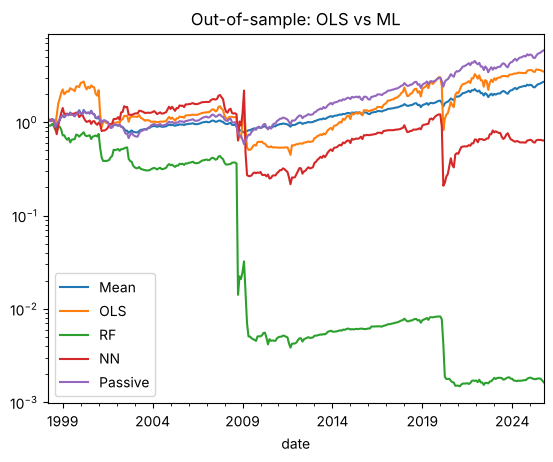

In [9]:
ML_OOS = pd.DataFrame({'Mean': NULL, 'OLS': F_OOS['ALL'], 'RF': oos(RF_ML, MODELS['ALL']),
                       'NN': oos(NN_ML, MODELS['ALL'], scale=True)}).dropna()
S_ML_OOS = strategies(ML_OOS)
display(r2_oos(ML_OOS), stats(S_ML_OOS), S_ML_OOS.corr())
(1 + S_ML_OOS).cumprod().plot(logy=True, title='Out-of-sample: OLS vs ML'); plt.show()

# Part II. GMO

In [10]:
FILE2 = 'gmo_returns_weekly.xlsx'
W = 52
read = lambda s: pd.read_excel(FILE2, sheet_name=s, index_col=0)
R = pd.concat([read('gmo'), read('benchmarks'), read('indexes')], axis=1, sort=True)
R['GBI'] = 0.65 * R['MXWD'] + 0.35 * R['LBUSTRUU']
RF = (read('rates')['USGG3M'] / W).shift(1).reindex(R.index)  # no SHV in the file: 3M T-bill yield, lagged
RX = R.sub(RF, axis=0)
FUNDS = ['GMWAX', 'GBMFX', 'GQETX', 'GMGEX']
FACTORS = ['SPY', 'EFA', 'EEM', 'TLT', 'TIP']
SUBS = {'Start-2011': (None, '2011'), '2012-End': ('2012', None)}
sr = lambda r: r.mean() / r.std() * np.sqrt(W)

def tail(R, p=W):
    out = {}
    for c in R:
        r = R[c].dropna(); w = (1 + r).cumprod()
        out[c] = {'start': r.index[0], 'mean': r.mean() * p, 'vol': r.std() * np.sqrt(p), 'sharpe': sr(r),
                  'min': r.min(), 'q(.05)': r.quantile(.05), 'max drawdown': (w / w.cummax().clip(lower=1) - 1).min()}
    return pd.DataFrame(out).T

def lfd(y, X, p=W):
    d = pd.concat([y, X], axis=1).dropna()
    fit = sm.OLS(d.iloc[:, 0], sm.add_constant(d.iloc[:, 1:])).fit()
    a = fit.params.iloc[0]
    return pd.Series({'alpha': a * p, 't(alpha)': fit.tvalues.iloc[0]}
                     | {f'beta {c}': b for c, b in fit.params.iloc[1:].items()}
                     | {'r-squared': fit.rsquared, 'resid vol': fit.resid.std() * np.sqrt(p),
                        'info ratio': a * p / (fit.resid.std() * np.sqrt(p))})

# 2. Analyzing GMO's flagship fund
## 2.1

In [11]:
S2 = RX.loc[RX['GMWAX'].notna(), ['GMWAX', 'GBI', 'SPY']]
display(tail(S2), S2.corr())

,start,mean,vol,sharpe,min,q(.05),max drawdown
GMWAX,1996-11-01 00:00:00,0.048667,0.104325,0.466491,-0.105506,-0.021799,-0.317548
GBI,1996-11-01 00:00:00,0.053627,0.110723,0.484334,-0.137203,-0.022061,-0.409859
SPY,1996-11-01 00:00:00,0.089134,0.17834,0.499798,-0.198023,-0.038577,-0.598937


,GMWAX,GBI,SPY
GMWAX,1.000000,0.862545,0.777910
GBI,0.862545,1.000000,0.930101
SPY,0.777910,0.930101,1.000000


## 2.2

In [12]:
display(pd.DataFrame({b: lfd(RX['GMWAX'], RX[[b]]).rename({f'beta {b}': 'beta'}) for b in ['SPY', 'GBI']}).T)
lfd(S2['GBI'], S2[['SPY']])['beta SPY']

,alpha,t(alpha),beta,r-squared,resid vol,info ratio
SPY,0.008105,0.665329,0.455061,0.605144,0.065555,0.12364
GBI,0.005084,0.518334,0.812700,0.743983,0.052787,0.09631


np.float64(0.5774592517423961)

# 3. Other GMO funds
## 3.1

,GMWAX,GBMFX,GQETX,GMGEX,SPY,MXWD,LBUSTRUU
GMWAX,1.000000,0.938828,0.869641,0.951838,0.876026,0.929521,0.118485
GBMFX,0.938828,1.000000,0.756482,0.876474,0.755405,0.817245,0.076973
GQETX,0.869641,0.756482,1.000000,0.883641,0.943408,0.892931,0.038842
GMGEX,0.951838,0.876474,0.883641,1.000000,0.900139,0.934560,0.020354
SPY,0.876026,0.755405,0.943408,0.900139,1.000000,0.951864,0.006487
MXWD,0.929521,0.817245,0.892931,0.934560,0.951864,1.000000,0.049122
LBUSTRUU,0.118485,0.076973,0.038842,0.020354,0.006487,0.049122,1.000000


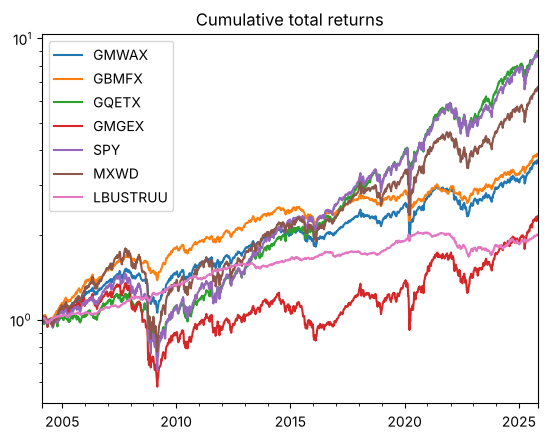

In [13]:
C = RX[FUNDS + ['SPY', 'MXWD', 'LBUSTRUU']].dropna()
display(C.corr())
(1 + R.loc[C.index, C.columns]).cumprod().plot(logy=True, title='Cumulative total returns'); plt.show()

## 3.2

In [14]:
display(tail(RX[FUNDS + ['SPY']]))
pd.DataFrame({f: lfd(RX[f], RX[['SPY']]).rename({'beta SPY': 'beta'}) for f in FUNDS}
             | {'GMGEX on MXWD': lfd(RX['GMGEX'], RX[['MXWD']]).rename({'beta MXWD': 'beta'})}).T

,start,mean,vol,sharpe,min,q(.05),max drawdown
GMWAX,1996-11-01 00:00:00,0.048667,0.104325,0.466491,-0.105506,-0.021799,-0.317548
GBMFX,2003-08-01 00:00:00,0.056142,0.079128,0.709501,-0.096358,-0.016517,-0.239062
GQETX,2004-02-13 00:00:00,0.094612,0.148276,0.638077,-0.171408,-0.030067,-0.406273
GMGEX,1996-12-06 00:00:00,0.029211,0.156913,0.18616,-0.165069,-0.035318,-0.583295
SPY,1996-01-12 00:00:00,0.090489,0.177185,0.510705,-0.198023,-0.036959,-0.598937


,alpha,t(alpha),beta,r-squared,resid vol,info ratio
GMWAX,0.008105,0.665329,0.455061,0.605144,0.065555,0.123640
GBMFX,0.020900,1.880368,0.343105,0.562463,0.052341,0.399298
GQETX,0.015303,1.448178,0.802164,0.890018,0.049174,0.311206
GMGEX,-0.035417,-2.275246,0.743892,0.715903,0.083636,-0.423465
GMGEX on MXWD,-0.029528,-2.327505,0.836923,0.811059,0.068206,-0.432925


# 4. GMO across subsamples
## 4.1

In [15]:
X4 = RX.loc[RX['GMWAX'].first_valid_index():]
SR = {}
for k, (a, b) in SUBS.items():
    sub = X4.loc[a:b]
    SR[(k, 'fund')] = sub[FUNDS + ['SPY']].apply(sr)
    SR[(k, 'SPY, same weeks')] = pd.Series({f: sr(sub.loc[sub[f].notna(), 'SPY']) for f in FUNDS})
pd.DataFrame(SR).loc[FUNDS + ['SPY']]

Start-2011                  2012-End                
            fund SPY, same weeks      fund SPY, same weeks
GMWAX   0.436020        0.234512  0.505568        0.867001
GBMFX   1.141893        0.240264  0.459306        0.867001
GQETX   0.172475        0.162706  0.912923        0.867001
GMGEX  -0.011713        0.210595  0.411898        0.867001
SPY     0.234512             NaN  0.867001             NaN

## 4.2

In [16]:
pd.concat({k: pd.DataFrame({f: lfd(X4.loc[a:b, f], X4.loc[a:b, ['SPY']]) for f in FUNDS}).T[['alpha', 'beta SPY', 'info ratio']]
           for k, (a, b) in SUBS.items()}, axis=1)

Start-2011                       2012-End                     
           alpha  beta SPY info ratio     alpha  beta SPY info ratio
GMWAX   0.029455  0.404562   0.384451 -0.024588  0.541450  -0.516056
GBMFX   0.073468  0.300734   1.490567 -0.015636  0.384888  -0.295554
GQETX   0.003215  0.701103   0.057599  0.011476  0.894364   0.289186
GMGEX  -0.029616  0.673703  -0.324609 -0.054706  0.861791  -0.773312

## 4.3

,start,cumulative,annualized,"SPY ann., same weeks","T-bill ann., same weeks"
GMWAX,2001-01-05 00:00:00,1.05213,0.074239,0.014178,0.021835
GBMFX,2003-08-01 00:00:00,1.309713,0.118727,0.051466,0.021561
GQETX,2004-02-13 00:00:00,0.171,0.023064,0.03426,0.022526
GMGEX,2001-01-05 00:00:00,0.188227,0.017329,0.014178,0.021835
SPY,2001-01-05 00:00:00,0.151799,0.014178,0.014178,0.021835
TLT,2002-08-02 00:00:00,0.670325,0.062505,0.067046,0.020496
LBUSTRUU,2001-01-05 00:00:00,0.763334,0.05813,0.014178,0.021835
RF,2001-01-05 00:00:00,0.242129,0.021835,0.014178,0.021835


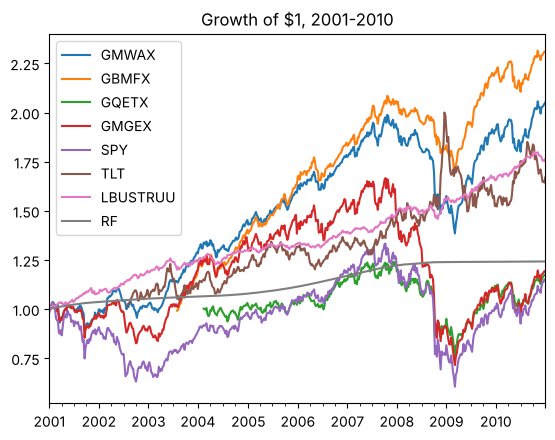

In [17]:
DEC = R.loc['2001':'2010', FUNDS + ['SPY', 'TLT', 'LBUSTRUU']].assign(RF=RF.loc['2001':'2010'])
ann = lambda r: (1 + r).prod() ** (W / len(r)) - 1
display(pd.DataFrame({c: {'start': DEC[c].first_valid_index(), 'cumulative': (1 + DEC[c].dropna()).prod() - 1,
                          'annualized': ann(DEC[c].dropna()), 'SPY ann., same weeks': ann(DEC.loc[DEC[c].notna(), 'SPY']),
                          'T-bill ann., same weeks': ann(DEC.loc[DEC[c].notna(), 'RF'])} for c in DEC}).T)
pd.DataFrame({c: (1 + DEC[c].dropna()).cumprod() for c in DEC}).plot(title='Growth of $1, 2001-2010'); plt.show()

# 5. Factor exposures
## 5.1

In [18]:
lfd(RX['GMWAX'], RX[FACTORS])

alpha         0.006474
t(alpha)      0.915895
beta SPY      0.157723
beta EFA      0.284114
beta EEM      0.064343
beta TLT      0.028029
beta TIP      0.089062
r-squared     0.885986
resid vol     0.032878
info ratio    0.196914
dtype: float64

## 5.3

In [19]:
lfd(RX['GBMFX'], RX[FACTORS])

alpha         0.023447
t(alpha)      2.580296
beta SPY      0.043835
beta EFA      0.204182
beta EEM      0.096704
beta TLT     -0.011670
beta TIP      0.098666
r-squared     0.713833
resid vol     0.042265
info ratio    0.554755
dtype: float64

## 5.4

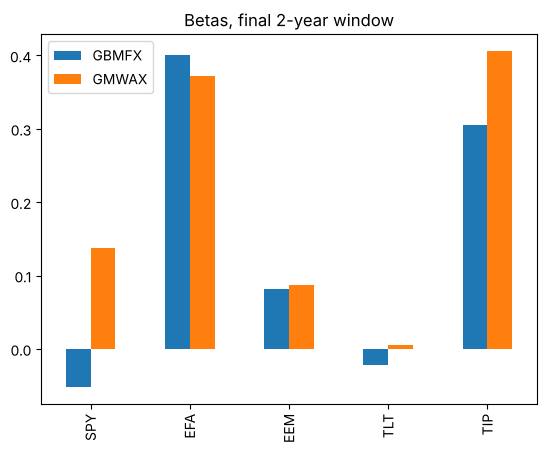

,SPY,EFA,EEM,TLT,TIP
GBMFX,-0.052236,0.401004,0.081658,-0.021921,0.304704
GMWAX,0.137287,0.371874,0.087178,0.005607,0.405719


In [20]:
def rolling(f):
    d = RX[[f] + FACTORS].dropna()
    return RollingOLS(d[f], sm.add_constant(d[FACTORS]), window=2 * W).fit().params[FACTORS].dropna()

ROLL = {f: rolling(f) for f in ['GBMFX', 'GMWAX']}
FINAL = pd.DataFrame({f: ROLL[f].iloc[-1] for f in ROLL})
FINAL.plot.bar(title='Betas, final 2-year window'); plt.show()
FINAL.T

## 5.5

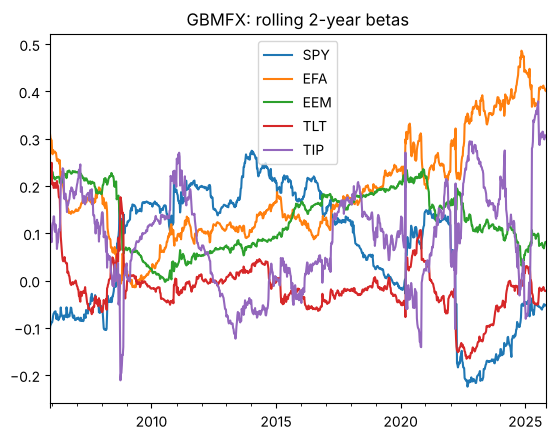

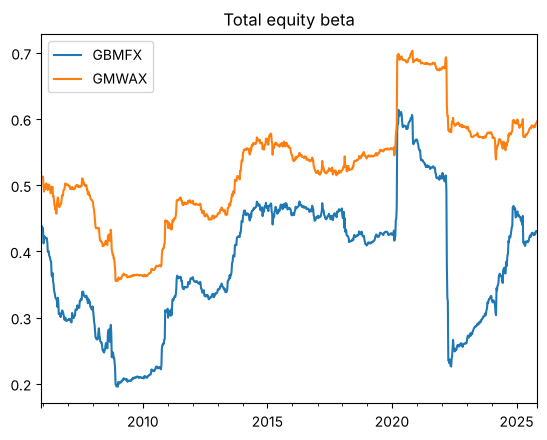

,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
SPY,-0.094922,-0.073889,-0.061259,0.013292,0.152148,0.152852,0.190469,0.170005,0.198012,0.237624,...,0.190086,0.133873,0.064743,0.008001,0.069253,0.133370,-0.139471,-0.181722,-0.113169,-0.053751
EFA,0.302059,0.198380,0.170402,0.072572,0.003972,0.066858,0.104986,0.108401,0.108223,0.140228,...,0.112102,0.155299,0.181923,0.219173,0.270108,0.235388,0.299266,0.363796,0.407974,0.403585
EEM,0.228882,0.222394,0.207331,0.171861,0.050269,0.014082,0.045786,0.062521,0.070214,0.083722,...,0.160464,0.166489,0.178143,0.194809,0.217280,0.160930,0.147060,0.112861,0.087400,0.080760
TLT,0.243947,0.080096,-0.041939,0.025070,-0.002040,-0.028930,-0.010559,-0.001617,0.014707,0.024683,...,-0.051532,-0.028504,-0.018297,-0.021068,0.033936,-0.022610,-0.124347,-0.100167,-0.018814,-0.015374
TIP,0.087293,0.160480,0.164557,0.007632,0.075526,0.151359,0.163387,0.010799,-0.075131,-0.042434,...,0.023582,0.125635,0.153194,0.090885,-0.009814,0.115650,0.169822,0.192925,0.101795,0.210245


In [21]:
ROLL['GBMFX'].plot(title='GBMFX: rolling 2-year betas'); plt.show()
pd.DataFrame({f: ROLL[f][['SPY', 'EFA', 'EEM']].sum(axis=1) for f in ROLL}).plot(title='Total equity beta'); plt.show()
ROLL['GBMFX'].groupby(ROLL['GBMFX'].index.year).mean().T

# 6. Forecasts
## 6.1

In [22]:
GMO_FC = pd.Series({'SPY': -.020, 'EFA': -.005, 'EEM': -.032, 'TLT': -.009, 'TIP': .000,
                    'IJR': -.020, 'GWX': -.011, 'EMB': .021, 'BWX': -.028})
H = RX.loc['2015-07':'2022-06', GMO_FC.index]
CHK = pd.DataFrame({'GMO forecast (real)': GMO_FC, 'realized mean': H.mean() * W,
                    'realized compounded': (1 + H).prod() ** (W / len(H)) - 1})
CHK['miss'] = CHK['realized mean'] - CHK['GMO forecast (real)']
display(CHK, (H.index[0], H.index[-1], len(H)))
pd.Series({'corr': CHK.iloc[:, 0].corr(CHK.iloc[:, 1]), 'rank corr': CHK.iloc[:, 0].corr(CHK.iloc[:, 1], method='spearman')})

,GMO forecast (real),realized mean,realized compounded,miss
SPY,-0.020,0.114078,0.103215,0.134078
EFA,-0.005,0.032416,0.016942,0.037416
EEM,-0.032,0.035709,0.015290,0.067709
TLT,-0.009,0.018626,0.009815,0.027626
TIP,0.000,0.022040,0.020836,0.022040
IJR,-0.020,0.097862,0.071863,0.117862
GWX,-0.011,0.035940,0.019087,0.046940
EMB,0.021,0.008558,0.003215,-0.012442
BWX,-0.028,-0.014292,-0.017089,0.013708


(Timestamp('2015-07-03 00:00:00'), Timestamp('2022-06-24 00:00:00'), 365)

corr        -0.276682
rank corr   -0.326363
dtype: float64

## 6.2

In [23]:
WGT = pd.concat({'Passive': pd.Series(1.0, index=Y.index)} | {f'{k} (IS)': 100 * F_IS[k] for k in MODELS}
                | {f'{k} (OOS)': 100 * F_OOS[k] for k in MODELS}, axis=1)
S6 = WGT.mul(Y, axis=0).loc['2000':'2011']
display(pd.DataFrame({'Sharpe 2000-2011': S6.mean() / S6.std() * np.sqrt(P), 'cumulative excess return': (1 + S6).prod() - 1,
                      'weight 1999': WGT.loc['1999'].mean(), 'weight 2000-2002': WGT.loc['2000':'2002'].mean(),
                      'weight 2008-2009': WGT.loc['2008':'2009'].mean()}))
(100 * F_OOS['ALL']).loc['2008-09':'2009-06']

,Sharpe 2000-2011,cumulative excess return,weight 1999,weight 2000-2002,weight 2008-2009
Passive,-0.031776,-0.199563,1.000000,1.000000,1.000000
DP (IS),0.186398,0.228225,0.171121,0.257429,1.403042
EP (IS),0.147715,0.134524,0.250972,0.439246,1.198565
ALL (IS),0.750008,4.137376,-0.699358,-1.090371,1.026182
DP (OOS),-0.188072,-0.286863,1.699919,0.662035,0.787541
EP (OOS),0.014520,-0.089576,0.803057,0.583561,0.898980
ALL (OOS),-0.113649,-0.760202,1.302598,1.097803,-0.404336


date
2008-09-30    0.064958
2008-10-31    2.598480
2008-11-30   -1.902014
2008-12-31   -6.062191
2009-01-31   -5.516584
2009-02-28   -4.840679
2009-03-31   -5.319597
2009-04-30   -3.649664
2009-05-31   -1.047820
2009-06-30   -0.134074
Name: ALL, dtype: float64